## Packages

# Setup

In [5]:
import numpy as np
import matplotlib
from astropy import units as u
import scipy.integrate
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable
from astropy.time import Time, TimeDelta
from scipy.sparse import coo_matrix
import copy
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from mpl_toolkits.axes_grid1 import AxesGrid, make_axes_locatable
from scipy import special
from scipy.sparse import coo_matrix
from scipy.ndimage import rotate
from astropy.cosmology import FlatLambdaCDM
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
import math
import jax
from scipy.stats import qmc
plt.rcParams['mathtext.fontset'] =  "cm"
plt.rcParams['font.family'] =  "serif"
import jax.numpy as jnp
jax.config.update("jax_enable_x64", True)
from scipy.signal import savgol_filter
import corner
from matplotlib import ticker

### constants ###
G=6.6743 * 10**(-8) #cm3 g-1 s-2
c=3e10 #cm/s
h=6.6261e-27 #cm2 g s-1
hbar=h/(2*np.pi)
K=1.3807e-16 #cm2 g s-2 K-1
T_500 = 28776
ZP_791 = 1.23e-9               # erg cm^2 s^-1 A^-1
wavelength_791 = 7969e-8       # cm
mag_fit = 6.86
kappa_star = 0.05
kappa_bulk = 0.38479219
gamma1 = 0.25426193864
gamma2 = 0.4098991987
z_s = 3.62
z_l = 0.34
Dq = 4.6e27  
rad_to_arcsec=2.0626e+11 #really rad to micro arcseconds

data=np.load('../macro_lens_results.npz')
#from IPython.display import FileLink
B_matrix=data['inv_jacobian_fit'][0]


## Remaining Parameters

In [6]:
D_l=cosmo.angular_diameter_distance(z_l).value*u.Mpc.to(u.cm)
D_s = cosmo.angular_diameter_distance(z_s).value*u.Mpc.to(u.cm)
D_ls=cosmo.angular_diameter_distance_z1z2(z_l, z_s).value*u.Mpc.to(u.cm)

print("D_s = {:.3e} cm".format(D_s))
print("D_l = {:.3e} cm".format(D_l))
print("D_ls = {:.3e} cm".format(D_ls))

D_s = 4.603e+27 cm
D_l = 3.085e+27 cm
D_ls = 3.708e+27 cm


# Functions

## Flux and angular radius

In [3]:
## Defining quasar functions ###
def flux_from_mag(mag, ZP):    
    flux=ZP*10**(-.4*mag)*1e8 #cm, not angstrom
    return flux
def R_from_flux(flux, distance, z, wavelength):
    flux_den_const=4*np.pi*1.93216*(h**(-5/3))*c**(-2/3)*K**(8/3)
    T_500=28776
    theta_500=np.sqrt(flux/(flux_den_const*(T_500**(8/3))*wavelength**(-7/3)))
    R_500=theta_500*(distance*(1+z)**(4/3))
    return theta_500, R_500

flux_791 = flux_from_mag(15.88, ZP_791)
theta_500_791, R_500_791 = R_from_flux(flux_791, Dq, z_s,  wavelength_791) #gives theta_lensed, R lensed (not physically meaningful)
theta_500_791_UL = theta_500_791/np.sqrt(mag_fit) #unlensed angular size, use for normalization 
#R_500_791 /= mag_fit
theta_500 = theta_500_791_UL

theta_E_1 = np.array([np.sqrt(4 * G * (2e33) / c**2 * D_ls / (D_s * D_l))])
theta_E_4 = np.array([np.sqrt(4 * G * (0.4 * 2e33) / c**2 * D_ls / (D_s * D_l))])


## Intensity, interferometry, and error

In [4]:
def get_I(mag, deltav):
    """
    Go from magnitude to Intensity as defined in equation 2.48 of https://arxiv.org/pdf/2307.06989
    KVT: What is deltav? What are the units of the output?
    """
    zeropt= 2635e-23 #3.631e-20 #
    flux_den=(zeropt)*10**(-.4*mag) #erg/s/cm2/Hz
    #Ephot=(h*c)/wavelength #ergs, wavelength in cm
    #f_photon_v=flux_den/Ephot

    return flux_den*deltav


def error_C(mag, wavelength, R, sigma_t=30e-12, t_obs=1e4, eta1=.5, eta2=.5, A=(200**2)*np.pi, mag_I=True):
    """
    Define error on our intensity interferometer according to equation 2.48 in https://arxiv.org/pdf/2307.06989
    Everything should be in cgs 
    """

    #R= kbar/sigma_k
    #first calculate the frequency bandidth sigma_f
    kbar=(2*np.pi)/wavelength #angular wavenumber
    sigma_f = (kbar*c)/(R*2*np.pi)

    #get I in units of g/s^3 (weird but cancels right)
    if mag_I:
        I1 = get_I(mag, sigma_f) 
    else:
        I1=mag
    #print(I1)
    sigma_c = np.sqrt(1/(np.sqrt(4*np.pi)*sigma_t*t_obs))*(hbar*c*kbar)/(I1*np.sqrt(eta1*eta2*(A**2)))
    return sigma_c

sigma_C = error_C(mag=16.5, wavelength=500*1e-7, R = 2e4, sigma_t=3e-12, A=10*(500**2)*np.pi, t_obs= 8 * 3600)
print('sigma_C = {:2g}'.format(sigma_C)) # error on C at 500 nm

sigma_C = 9.21273


In [5]:
def calcC_sparse(sparse_image, theta_step, box_size=2e10, max_norm=True, ellipse=True):
    """
    Calculate the absolute square of the Fourier transform of a sparse image and extract a region of fixed size in uv-space.

    Parameters:
        sparse_image: scipy.sparse matrix
        theta_step: original step size of our image in radians before any padding
        box_size: desired size of box. **This is no longer being used in this version of the code**
        max_norm: bool, fixed normalization from an earlier version
        ellipse: full image or just some sampled points in the ellipse?
    Returns:
        2D array of the normalized power spectrum region or sampled ellipse points of that (if ellipse=True)
    """
    csr_image = sparse_image.tocsr()
    N_padded = csr_image.shape[0]  # after any padding
    N_orig = sparse_image.shape[0] if not hasattr(sparse_image, "pad_origin_shape") else sparse_image.pad_origin_shape

    dense_image = csr_image.toarray()

    # Correct theta_step if padded
    theta_step_eff = theta_step * N_orig / N_padded

    # FFT and power spectrum
    dense_image_jax = jnp.asarray(dense_image, dtype=jnp.complex128)
    
    fourier_transform = jnp.fft.fftshift(jnp.fft.fft2(dense_image_jax)) #jnp.fft.fftshift(jnp.fft.fft2(dense_image, workers=-1))
    correlation = jnp.abs(fourier_transform) ** 2
    #correlation=jnp.flipud(correlation)
    u_vals = 2 * jnp.pi * jnp.fft.fftshift(jnp.fft.fftfreq(N_padded, d=theta_step_eff))
    v_vals = u_vals.copy()  # square FFT, so same axis
    if max_norm:
        tot = jnp.max(correlation)
    else:
        tot = jnp.nansum(correlation)

    correlation = correlation / tot

    if not ellipse:
        return u_vals, v_vals, correlation
        
    if ellipse:
        _, _, _, uv_ellipse=get_uv_elipse(correlation, u_vals, v_vals)
    
        u_indices = jnp.searchsorted(u_vals, uv_ellipse[:, 0]) - 1
        v_indices = jnp.searchsorted(v_vals, uv_ellipse[:, 1]) - 1
    
        # Clip to valid bounds
        u_indices = jnp.clip(u_indices, 0, len(u_vals) - 1)
        v_indices = jnp.clip(v_indices, 0, len(v_vals) - 1)
        
        # Gather values, swap u and v because of how we index (xy vs ij indexing causes this and I've checked many times to make sure we
        # should be doing this) 
        sampled_corr_vals = correlation[v_indices, u_indices] 
        return u_indices, v_indices, sampled_corr_vals


def get_uv_elipse(corr_uv, u_vals, v_vals, numpts=1000, limit=0.1): 
    """
    Fit an ellipse to corr_uv > limit (u,v centered).
    Return ellipse params (a, b, phi) and sample numpts points *inside* the ellipse.
    """
   # Build meshgrid and apply threshold
    U, V = jnp.meshgrid(u_vals, v_vals, indexing='ij')
    mask = corr_uv > limit
    u_points = U[mask]
    v_points = V[mask]

    if len(u_points) < 5:
        num_thresh_pts = len(u_points)
        print(f"Not enough points above threshold to fit ellipse. Only {num_thresh_pts} points")

    coords = jnp.vstack([u_points, v_points])

    # Covariance and eigen-decomposition
    cov = np.cov(coords)
    evals, evecs = jnp.linalg.eigh(cov)

    # Sort eigenvalues (major => minor)
    order = jnp.argsort(evals)[::-1]
    evals = evals[order]
    evecs = evecs[:, order]

    a = jnp.sqrt(evals[0])
    b = jnp.sqrt(evals[1])
    phi = jnp.arctan2(evecs[1, 0], evecs[0, 0])  # angle in radians

    # Determine grid resolution
    numpts_per_axis = int(jnp.sqrt(numpts))

    sampler = qmc.Halton(d=2, scramble=False)
    points = sampler.random(n=numpts)

    # Map unit square [0,1] x [0,1] to unit circle
    r = jnp.sqrt(points[:, 0])
    theta = 2 * jnp.pi * points[:, 1]
    u_inner =  a * r * jnp.cos(theta)
    v_inner =  b * r * jnp.sin(theta)
    
    # Rotate
    rot = jnp.array([[jnp.cos(phi), -jnp.sin(phi)],
                     [jnp.sin(phi),  jnp.cos(phi)]])
    ellipse_points = rot @ jnp.vstack([u_inner, v_inner])
    sampled_uv = ellipse_points.T

    return a, b, phi, sampled_uv

## Image helpers

In [6]:
def pad_image(image, npad):
    """
    Pad an image with zeros to increase resolution when tranformed to UV space
    """
    if npad==0:
        return image
    if scipy.sparse.issparse(image):
        image_padded = np.pad(image.toarray(), npad, mode='constant', constant_values=0)
        return scipy.sparse.csr_matrix(image_padded)  # Returning as a sparse matrix
    else:
        return jnp.pad(image, npad, mode='constant', constant_values=0)

def numerical_dCdr(g_params, star_params, arr_theta, rad, theta_max, beta_min,
                   quasar_int_func, theta_step, N_step, delta_r=1e-13, circle=False, pad_frac=0):
    """
    Compute the numerical partial derivative of the correlation function w.r.t. rad.
    Uses central finite difference.

    Returns:
        dC_dr: 2D array of same shape as correlation function
    """
    def compute_corr(radiusval, cirlce, pad_frac):
        alpha, beta_ = beta(g_params, star_params, arr_theta)
        #N_0=len(beta_[0])
        #theta_step_eff = theta_step * N_0 / (N_0 + 2 * (pad_frac*N_0))

        if cirlce:
            img=color_in_circ(beta_, radiusval, theta_max)
            padded_img = pad_image(img, int(pad_frac* N_step))
            N = padded_img.shape[0]
            u_vals = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(N, d=theta_step))
            u_max = np.max(np.abs(u_vals))
            corr = calcC(padded_img, theta_step, box_size=u_max)
        else:
            img, _, _ = sparse_quasar_image(beta_, radiusval, theta_max, beta_min, quasar_int_func)
            padded_img = pad_image(img, int(pad_frac * N_step))
            csr_image = padded_img.tocsr()
            N = csr_image.shape[0]
            u_vals = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(N, d=theta_step))
            u_max = np.max(np.abs(u_vals))
            _,_, corr = calcC_sparse(padded_img, theta_step, box_size=2*u_max, ellipse=False)
        return corr
    # Compute forward and backward correlation functions
    C_forward = compute_corr(rad + delta_r, circle, pad_frac)
    C_backward = compute_corr(rad - delta_r, circle, pad_frac)
    # Numerical derivative
    dC_dr = (C_forward - C_backward) / (2 * delta_r)
    return dC_dr

def get_opt_pt(dCdr, theta_step):
    """
    returns index of dCdr where the derivative is at a maximum
    """
    u_max=np.max(2 * np.pi * np.fft.fftshift(np.fft.fftfreq(len(dCdr[0]), d=theta_step)))
    extent = [-u_max, u_max, -u_max, u_max]  # [u_min, u_max, v_min, v_max]

    # Mark the minimum (pixel-based index to coordinate)
    max_idx = np.unravel_index(np.argmax(np.abs(dCdr)), dCdr.shape)
    max_u = extent[0] + (extent[1] - extent[0]) * max_idx[1] / dCdr.shape[1]
    max_v = extent[2] + (extent[3] - extent[2]) * max_idx[0] / dCdr.shape[0]

    return  np.asarray(max_idx), np.asarray((max_u, max_v))

def place_star_radial(star_masses, fraction, angle=np.pi/4, image_size=7000, phi_0=-2.078586999806823, theta_max=2e-10):
    """
    Cleanly handle units and everything so we can give a fraction f and this will return the indicies we should put a star of mass m at 
    so that it is at f*theta_E for that star, and a 7000 x 7000 image (by default) 
    default angle is along the 45 in the second quadrant (arb)
    """
    N_step = image_size
    theta_step = 2 * theta_max / image_size

    # Einstein radius (radians)
    theta_E = jnp.array([
        jnp.sqrt(4 * G * (star_masses * u.solMass.to(u.gram)) / c**2 * D_ls / (D_s * D_l))
    ])

    # radial coordinate in radians
    r_vals = fraction * theta_E

    # angular coordinate
    theta = phi_0 + np.pi / 2
    phi = np.array((np.pi - theta - angle))

    # meshgrid (keeps same output shape as before)
    rr, pp = np.meshgrid(r_vals, phi, indexing='ij')

    # Cartesian (radians)
    x = rr * np.cos(pp)
    y = rr * np.sin(pp)

    positions_plot = np.stack([x.flatten(), y.flatten()], axis=1)

    # map [-theta_max, +theta_max] → [0, image_size]  (same shape as before)
    return ((positions_plot / (2 * theta_max)) + 0.5) * image_size

## Microlensing

In [7]:
def alpha_g(kappa, shear1, shear2, theta):
    """
    Calculate the smooth (global) deflection field.
    Inputs:
        theta: shape 2, N, N for a grid OR shape 2 for a single point
        shears and kappa: constants
    Output:
        Array of (x, y) positions, shape 2, N, N or shape 2 for a point
    """
    #theta = np.atleast_2d(theta)  # Convert to (2, N, N) if it's not already

    theta_x = theta[0]
    theta_y = theta[1]
    # Calculate deflections for each position
    alpha_x = (kappa + shear1) * theta_x + shear2 * theta_y  
    alpha_y = (kappa - shear1) * theta_y + shear2 * theta_x  

    return np.array([alpha_x, alpha_y])  # Output shape: (2, N, N) or (2,)
    
 
def alpha_pt(const, arr_theta):
    """
    In current code, we don't use this
    Deflection angle of a point mass at coordinates each point in arr_theta.
    Inputs:
        const: constant related to point mass
        arr_theta: shape 2, 2N-1, 2N-1 for a grid OR shape 2 for a single point
    Outputs:
        alpha: shape 2, 2N-1, 2N-1 or shape 2
    """
    norm_theta = jnp.linalg.norm(arr_theta, axis=0)
    mask = norm_theta > 0  # Avoid division by zero
    alpha = jnp.zeros_like(arr_theta)
    alpha=alpha.at[:, mask].set(const * arr_theta[:, mask] / norm_theta[mask]**2)
    return alpha


def alpha_many_stars(m_star, Ds, Dl, DLS, arr_theta, theta_max, arr_rand_idx):
    """
    Defelction from a single star, despite the name of the function.
    m_star should be in solar masses, and everything else should be in cgs units 
    """
    m_star=jnp.asarray(m_star)
    m_star=m_star*u.solMass.to(u.g)
    const = (4 * G * m_star / c**2) * (DLS / (Ds * Dl))
    ## bc of how we index (ie where we call 0) we need to shift the star by -theta_max so that a star at (0,0) is really at 
    # the center of the image, not the lower left corner
    arr_rand_idx=jnp.asarray(arr_rand_idx)
    arr_rand_idx-=theta_max 
    
    delta_theta_x=arr_theta[0]-arr_rand_idx.T[0]
    delta_theta_y=arr_theta[1]-arr_rand_idx.T[1]
    delta_theta = jnp.asarray((delta_theta_x, delta_theta_y))
    
    # Flatten arr_rand_idx to shape (2,)
    # Compute norm, avoid exact zero to prevent singularity issues
    norm_theta = jnp.linalg.norm(delta_theta, axis=0)
    eps = 1e-20  # tiny number to avoid division by zero
    safe_norm = jnp.where(norm_theta > 0, norm_theta, eps)

    alpha = const * delta_theta / safe_norm**2
    return alpha
    

def beta(gparams, star_params, theta):
    "subtracts defelction alpha off from theta, both of which are grids of shape 2,N,N"
    alpha_all= alpha_tot(gparams, star_params, theta)
    beta_pos = jnp.subtract(theta, alpha_all)
    return alpha_all, beta_pos

def alpha_tot(g_params, star_params, theta):
    """
    Calculate total alpha for both smooth deflection and point masses.
    Inputs:
        theta: grid or single point
    Outputs:
        Total deflection
    """
    kappa, shear1, shear2 = g_params
    m_stars, Ds, Dl, DLS, theta_max, arr_rand_idx= star_params
    alpha_gval = alpha_g(kappa, shear1, shear2, theta)
    alpha_stars = alpha_many_stars(m_stars, Ds, Dl,DLS, theta, theta_max, arr_rand_idx)
    return alpha_gval + alpha_stars

## Image generation

In [8]:
def get_rot_angle(coords):
    """
    Given a 2xN array of positions (e.g. beta positions),
    compute the orientation angle of the major axis.
    KVT: What does this function do exactly?
    """
    # Covariance and eigen-decomposition
    coords = coords.reshape(2, -1)
    cov = np.cov(coords)
    evals, evecs = np.linalg.eigh(cov)

    # Sort eigenvalues descending
    order = np.argsort(evals)[::-1]
    evals = evals[order]
    evecs = evecs[:, order]

    # Get angle of the major axis
    phi = np.arctan2(evecs[1, 0], evecs[0, 0])  # radians
    return phi

def quasar_int_sparse(x_coords, y_coords, radius, theta_max, N, wavelength=8.06e-5, quasar_pos=[0,0]):
    """
    Modified quasar intensity function to work with sparse coordinates
    Try something smoother here to isolate if this is causing the issue
    """
    const = 2*h*c**2
    theta_step = 2*theta_max/N #need N as a param because we don't have the full grid here
    
    beta_x, beta_y = jnp.array(quasar_pos)*theta_step
    beta_vals = jnp.sqrt((x_coords-beta_x)**2 + (y_coords-beta_y)**2)
    
    def T(theta):
        theta_min = theta_500#*.9
        return T_500*((theta+theta_min)/radius)**(-.75)
    
    B_of_theta = (1/(jnp.exp((h*c)/(wavelength*K*T(beta_vals)))-1))*(const/(wavelength**5))
    
    return B_of_theta

def sparse_quasar_image(beta_, radius, theta_max, beta_min, quasar_int_func, **kwargs):
    """
    beta_min: minimum beta value to consider
    Returns:
        sparse_image: scipy.sparse.coo_matrix
        coords: tuple of (row_indices, col_indices)
        values: intensity values at those coordinates
    """
    N = beta_[0].shape[0]
    
    beta_vals = jnp.sqrt(beta_[0]**2 + beta_[1]**2)
    
    # define 'interesting' regions
    mask = beta_vals < beta_min
    row_indices, col_indices = jnp.where(mask)
    selected_beta = (beta_[0][mask], beta_[1][mask])
    
    # Create a small grid just for the selected points
    selected_grid = jnp.zeros((2, len(row_indices)))
    selected_grid = jnp.stack([beta_[0][row_indices, col_indices], beta_[1][row_indices, col_indices]], axis=0)
    values = quasar_int_func(selected_grid[0], selected_grid[1], radius, theta_max,N, **kwargs)
    sparse_image = coo_matrix((values, (row_indices, col_indices)), shape=(N, N))
    
    return sparse_image, (row_indices, col_indices), values

In [9]:
def sparse_quasar_image_jax(beta_, radius, theta_max, beta_min, quasar_int_func, **kwargs):
    """
    JAX-friendly replacement for sparse_quasar_image.
    Returns:
        image: (N,N) jax array with intensities
        coords: tuple of (row_indices, col_indices)
        values: intensity values at those coordinates
    """
    N = beta_[0].shape[0]
    beta_vals = jnp.sqrt(beta_[0]**2 + beta_[1]**2)
    
    # Compute full image
    values = quasar_int_func(beta_[0], beta_[1], radius, theta_max, N, **kwargs)
    
    # Mask out unwanted values
    values = jnp.where(beta_vals < beta_min, values, 0.0)
    
    return values  # full (N,N) jax array

# Initial image generation

In [10]:
import gc 
gc.collect()

40

In [11]:
#define some constants, get angle of roation of macrolensing

theta_max = 2e-10 # (half) size of image
image_size=8000
N_step = image_size
theta_max = 2e-10
g_params=(kappa_bulk, gamma1, gamma2)
theta_step = 2 * theta_max / image_size
vec_theta = np.linspace(-theta_max, theta_max, N_step)
arr_theta = np.asarray(np.meshgrid(vec_theta, vec_theta, indexing='xy'))
rad = theta_500  # or rad = np.round(theta_500 / theta_step)
arr_rands = np.array([[int(image_size * .4), int(image_size * .5)]])
star_params = ([0], D_s, D_l, D_ls, theta_max, arr_rands)

alpha_, beta_ = beta(g_params, star_params, arr_theta)
phi_0=-get_rot_angle(beta_)

In [12]:
# get u,v, points for an 8000 x 8000 image
pad_frac=0
beta_min = .9e-11
image_0, _,_ = sparse_quasar_image(beta_, rad, theta_max, beta_min, quasar_int_sparse)
u_full,v_full, corr_0_full=calcC_sparse(image_0, theta_step, ellipse=False)
upts_8k, vpts_8k, corr_0 = calcC_sparse(image_0, theta_step, ellipse=True)
elps_pts=jnp.asarray((vpts_8k, upts_8k)) #reversed again, as we do in the corr_C function

In [13]:
# calcualte the ideal point for getting r_s measurements
pad_frac=0
dC_dr_test=numerical_dCdr(g_params, star_params, arr_theta, rad, theta_max, beta_min,
                   quasar_int_sparse, theta_step, N_step, delta_r=1e-14, circle=False)

theta_step_eff = theta_step * N_step / (N_step+(2*pad_frac*N_step))
ind, uv_opt=get_opt_pt(dC_dr_test, theta_step_eff)

In [14]:
four_maxes=np.sort(np.abs(dC_dr_test.ravel()))[-4:]

In [15]:
u_max=np.max(2 * np.pi * np.fft.fftshift(np.fft.fftfreq(len(dC_dr_test[0]), d=theta_step_eff)))
extent = [-u_max, u_max, -u_max, u_max]
arg_maxes=[]
max_us=[]
max_vs=[]
for max in four_maxes:
    arg_maxes.append(np.where(np.abs(dC_dr_test)==max))
    max_us.append(extent[0] + (extent[1] - extent[0]) * arg_maxes[-1][1] / dC_dr_test.shape[1])
    max_vs.append(extent[2] + (extent[3] - extent[2]) * arg_maxes[-1][0] / dC_dr_test.shape[0])


In [16]:
for i in range(len(max_us)):
    # location of the ideal r_s point in micro-as, and correlation value at each of those points (should be ~the same)
    print('max at (u,v) = ', max_us[i]/rad_to_arcsec, max_vs[i]/rad_to_arcsec, 'with value', corr_0_full[arg_maxes[i][0], arg_maxes[i][1]])

max at (u,v) =  [-1.14205636] [2.58866108] with value [0.45908604]
max at (u,v) =  [1.14205636] [-2.58866108] with value [0.45908604]
max at (u,v) =  [0.07613709] [-0.98978218] with value [0.45964307]
max at (u,v) =  [-0.07613709] [0.98978218] with value [0.45964307]


In [17]:
gc.collect()

20

### paper figures

In [18]:
#regenerate unlensed image, not strictly necessary
image_size = int(8000) # number of pixels
N_step = image_size
theta_max = 2e-10 # (half) size of image
theta_step = 2 * theta_max / image_size
vec_theta = jnp.linspace(-theta_max, theta_max, N_step)
arr_theta = jnp.asarray(jnp.meshgrid(vec_theta, vec_theta, indexing='xy'))
rad = theta_500 
arr_rands = jnp.array([[(300-239), (500-68)]])
m_stars = jnp.asarray([0.4])
positions = place_star_radial(m_stars, 0, image_size=image_size)

#unlensed image
alpha_0, beta_0 = beta(g_params, (jnp.asarray(0), D_s, D_l, D_ls, theta_max, arr_rands), arr_theta)
pad_frac=0
beta_min = 100e-11 #get full image this time, don't do this when actually computing derived quantities
image_0, _,_ = sparse_quasar_image(beta_0, rad, theta_max, beta_min, quasar_int_sparse)
u_full,v_full, corr_0_full=calcC_sparse(image_0, theta_step, ellipse=False)
upts_8k, vpts_8k, corr_0 = calcC_sparse(image_0, theta_step, ellipse=True)
elps_pts=jnp.asarray((vpts_8k, upts_8k)) #reversed again, as we do in the corr_C function
corr_0=corr_0_full[vpts_8k, upts_8k]
gc.collect()

189

In [31]:
(jnp.array([[10], [200]])*theta_step).reshape(1,2)*rad_to_arcsec

Array([[0.10313, 2.0626 ]], dtype=float64, weak_type=True)

In [19]:
## lensed image
arr_rands=(jnp.array([[4010], [4200]])*theta_step).reshape(1,2) #semi-random location, just illustrative
star_params_1 = (m_stars, D_s, D_l, D_ls, theta_max, arr_rands)
_, beta_1 = beta(g_params, star_params_1, arr_theta)
image_1, _, _=sparse_quasar_image(beta_1, theta_500, theta_max, beta_min, quasar_int_sparse)
_,_, corr_1_full=calcC_sparse(image_1, theta_step, ellipse=False)
corr_1=corr_1_full[vpts_8k, upts_8k]

#fully unlensed (not even macrolensing)
alpha_00, beta_00 = beta((0,0,0), (jnp.asarray(0), D_s, D_l, D_ls, theta_max, arr_rands), arr_theta)
image_00, _, _= sparse_quasar_image(beta_00, rad, theta_max, beta_min, quasar_int_sparse)
u_full,v_full, corr_00_full=calcC_sparse(image_00, theta_step, ellipse=False)
gc.collect()

0

In [20]:
#get each parameter derivative
dC_dr_lensed=numerical_dCdr(g_params, star_params_1, arr_theta, rad, theta_max, beta_min,
                   quasar_int_sparse, theta_step, N_step, delta_r=1e-14, circle=False)
gc.collect()

KeyboardInterrupt: 

In [ ]:
def numerical_dCdstarparam(g_params, star_params, arr_theta, rad, theta_max, beta_min, quasar_int_func, theta_step,
                            N_step, param="mass", delta=1e-8, circle=False, pad_frac=0):
    """
    Numerical partial derivative of the correlation function with respect to one
    star parameter using central finite differences.

    Parameters
    ----------
    star_params : tuple/list/array
        Expected format: (mass, x, y)
    param : str
        One of: "mass", "x", "y"
    delta : float
        Finite difference step size

    Returns
    -------
    dC_dparam : array
        Same shape as correlation function.
    """

    param_map = {"mass": 0, "x": 1, "y": 2}
    if param not in param_map:
        raise ValueError("param must be one of: 'mass', 'x', 'y'")

    idx = param_map[param]

    def compute_corr(star_params_local):
        alpha, beta_ = beta(g_params, star_params_local, arr_theta)

        if circle:
            img = color_in_circ(beta_, rad, theta_max)
            padded_img = pad_image(img, int(pad_frac * N_step))
            N = padded_img.shape[0]

            u_vals = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(N, d=theta_step))
            u_max = np.max(np.abs(u_vals))

            corr = calcC(padded_img, theta_step, box_size=u_max)

        else:
            img, _, _ = sparse_quasar_image(beta_, rad, theta_max, beta_min, quasar_int_func)

            padded_img = pad_image(img, int(pad_frac * N_step))
            csr_image = padded_img.tocsr()
            N = csr_image.shape[0]

            u_vals = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(N, d=theta_step))
            u_max = np.max(np.abs(u_vals))

            _, _, corr = calcC_sparse(padded_img, theta_step, box_size=2 * u_max, ellipse=False)

        return corr

    # forward params
    m_stars, D_s, D_l, D_ls, theta_max, arr_rands = star_params

    # unpack the single-star values you want to perturb
    star_params_deriv = np.array(
        [m_stars[0].item(),          # mass
            arr_rands[0][0].item(),    # x position
            arr_rands[0][1].item(),    # y position
        ], dtype=float)

    # central difference vectors
    star_fwd = star_params_deriv.copy()
    star_bwd = star_params_deriv.copy()

    star_fwd[idx] += delta
    star_bwd[idx] -= delta

    def rebuild_star_params(vals):
        """
        Reconstruct full star_params in original format after perturbing
        [mass, x, y].
        """
        new_m_stars = np.array(m_stars, copy=True)
        new_arr_rands = np.array(arr_rands, copy=True)

        new_m_stars[0] = vals[0]
        new_arr_rands[0, 0] = vals[1]
        new_arr_rands[0, 1] = vals[2]

        return (new_m_stars, D_s, D_l, D_ls, theta_max, new_arr_rands)

    C_forward = compute_corr(rebuild_star_params(star_fwd))
    C_backward = compute_corr(rebuild_star_params(star_bwd))

    dC_dparam = (C_forward - C_backward) / (2 * delta)

    return dC_dparam

In [23]:
# Convert sparse matrices to dense arrays for plotting
im_00 = np.log(image_00.todense()+1e-40)
im_0  = np.log(image_0.todense()+1e-40)
im_1  = np.log(image_1.todense()+1e-40)
u_vals = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(image_size, d=theta_step))
umax=np.max(u_vals)
max_x = 10*(np.array(place_star_radial(jnp.asarray(0.4), 10.2, angle=0,
                        image_size=image_size, phi_0=phi_0, theta_max=theta_max))/image_size-0.5)*theta_step*image_size

In [ ]:
#get each paramter derivative
dC_dmass=numerical_dCdstarparam(g_params, star_params_1, arr_theta, rad, theta_max, beta_min, quasar_int_sparse, 
                                theta_step, N_step, param="mass", delta=1e-6)
np.save("dC_dmass.npy", dC_dmass)
dC_dmass= np.load("dC_dmass.npy")

np.save("dC_dr_lensed.npy", dC_dr_lensed)
dC_dr_lensed = np.load("dC_dr_lensed.npy")
gc.collect()

0

In [21]:
dC_dmass= np.load("dC_dmass.npy")
dC_dr_lensed = np.load("dC_dr_lensed.npy")
dC_dx= np.load("dC_dx.npy")
dC_dy= np.load("dC_dy.npy")

In [ ]:
#get each paramter derivative
dC_dx=numerical_dCdstarparam(g_params, star_params_1, arr_theta, rad, theta_max, beta_min, quasar_int_sparse, 
                                theta_step, N_step, param="x", delta=1e-14)
gc.collect()
np.save("dC_dx.npy", dC_dx)
dC_dy=numerical_dCdstarparam(g_params, star_params_1, arr_theta, rad, theta_max, beta_min, quasar_int_sparse, 
                                theta_step, N_step, param="y", delta=1e-14)
gc.collect()
np.save("dC_dy.npy", dC_dy)

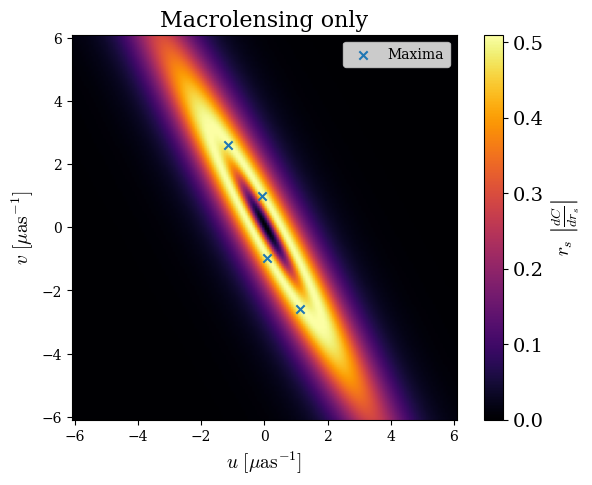

In [37]:
#zoom in
zoom = 50
ny, nx = corr_00_full.shape
cy, cx = ny//2, nx//2  # center
def zoom_in(arr, factor=zoom):
    half_y = ny // (2*factor)
    half_x = nx // (2*factor)
    return arr[cy-half_y:cy+half_y, cx-half_x:cx+half_x]

dC_dr_test_z = zoom_in(dC_dr_test)*rad

# Make the figure
fig, ax = plt.subplots(figsize=(7, 5))
extent_z =np.array( [-umax/zoom, umax/zoom, -umax/zoom, umax/zoom])/rad_to_arcsec
im=ax.imshow(np.abs(dC_dr_test_z), origin="lower", extent=extent_z, cmap="inferno")
cbar = plt.colorbar(im, ax=ax, fraction=.046)
cbar.set_label(r"$r_s\ \left|\frac{d C}{d r_s}\right| $", fontsize=14)
cbar.ax.tick_params(labelsize=14)
ax.set_title('Macrolensing only', fontsize=16)
ax.scatter(np.array(max_us)/rad_to_arcsec, np.array(max_vs)/rad_to_arcsec, label='Maxima', marker='x')
ax.legend()
ax.set_ylabel(r"$v \ [\mu \text{as}^{-1}]$", fontsize=14)
ax.set_xlabel(r"$u \ [\mu \text{as}^{-1}]$", fontsize=14)
        
plt.savefig('../Figures/macor_deriv.pdf', bbox_inches='tight')

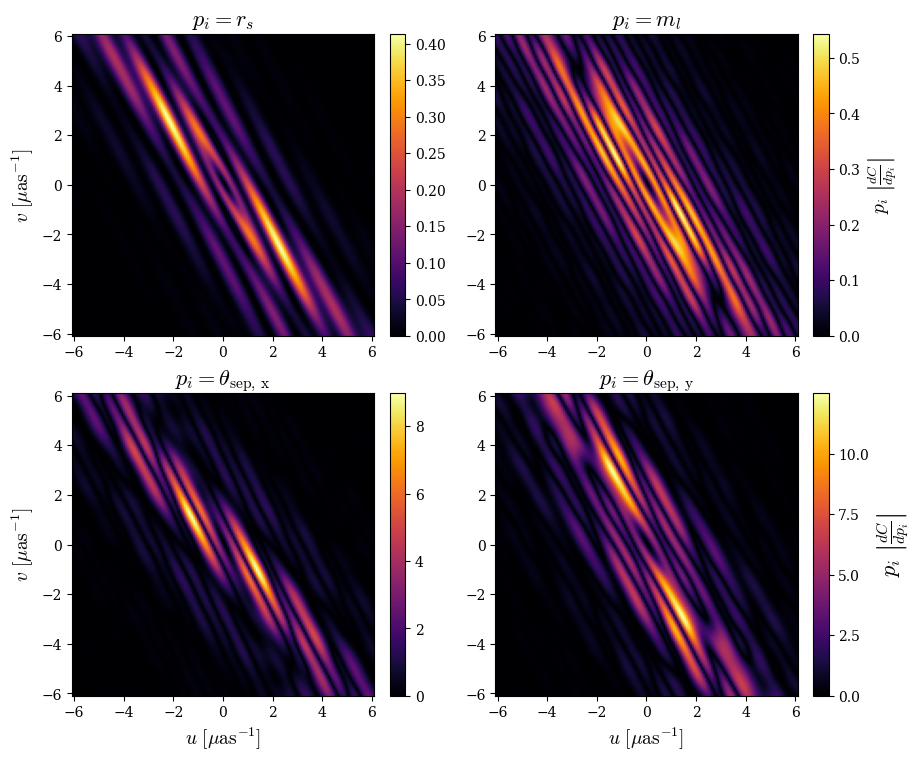

In [27]:
#zoom in
zoom = 50
ny, nx = corr_00_full.shape
cy, cx = ny//2, nx//2  # center
def zoom_in(arr, factor=zoom):
    half_y = ny // (2*factor)
    half_x = nx // (2*factor)
    return arr[cy-half_y:cy+half_y, cx-half_x:cx+half_x]

dC_dr_lensed_z = zoom_in(dC_dr_lensed)*rad
dC_dmass_z = zoom_in(dC_dmass)*star_params_1[0][0]
dC_dx_z = zoom_in(dC_dx)*star_params_1[-1][0][0]
dC_dy_z = zoom_in(dC_dy)*star_params_1[-1][0][1]


# Make the figure
fig, axes = plt.subplots(2, 2, figsize=(9, 7.5), constrained_layout=True)
#fig.text(0.48, 1.019, r'Real space images', ha='center', va='top', fontsize=15, transform=fig.transFigure)
imlist = [np.abs(dC_dr_lensed_z), np.abs(dC_dmass_z)]
imlist2 = [np.abs(dC_dx_z), np.abs(dC_dy_z)]

titles = [r"$p_i=r_s$", r"$p_i=m_l$"]
titles2 = [ r"$p_i=\theta_\text{sep, x}$", r"$p_i=\theta_\text{sep, y}$"]

vmin = np.min([im.min() for im in imlist])
vmax = np.max([im.max() for im in imlist])

extent_z =np.array( [-umax/zoom, umax/zoom, -umax/zoom, umax/zoom])/rad_to_arcsec
for i, ax in enumerate(axes[0, :]):
    implot = ax.imshow(imlist[i], origin="lower", extent=extent_z,cmap="inferno")
    #ax.set_xlabel(r"$u \ [\mu \text{as}^{-1}]$", fontsize=14)
    if i == 0:
        ax.set_ylabel(r"$v \ [\mu \text{as}^{-1}]$", fontsize=14)
    ax.set_title(titles[i],  fontsize=16)
        
    #ax.set_title(titles2[i])

    cbar = fig.colorbar(implot, location="right", fraction=0.05, pad=0.04)
    if i == 1 :
        cbar.set_label(r"$p_i\ \left|\frac{d C}{d p_i}\right| $", fontsize=14)

vmin2 = np.min([im.min() for im in imlist2])
vmax2 = np.max([im.max() for im in imlist2])
extent_z =np.array( [-umax/zoom, umax/zoom, -umax/zoom, umax/zoom])/rad_to_arcsec
for i, ax in enumerate(axes[1, :]):
    implot = ax.imshow(imlist2[i], origin="lower", extent=extent_z, cmap="inferno")
    ax.set_xlabel(r"$u \ [\mu \text{as}^{-1}]$", fontsize=14)
    if i == 0:
        ax.set_ylabel(r"$v \ [\mu \text{as}^{-1}]$", fontsize=14)
    ax.set_title(titles2[i], fontsize=16)
    cbar = fig.colorbar(implot, location="right", fraction=0.05, pad=0.04)
    tick_locator = ticker.MaxNLocator(nbins=5)
    cbar.locator = tick_locator
    cbar.update_ticks()
    if i == 1 :
        cbar.set_label(r"$p_i\ \left|\frac{d C}{d p_i}\right| $", fontsize=16)
        
#cbar2 = fig.colorbar(implot, ax=axes[1, :], location="right", fraction=0.0205, pad=0.04)
#cbar2.set_label(r"$\left|\frac{d C}{d p_i}\right| $", fontsize=14)
#plt.show()

plt.savefig('../Figures/derivs.pdf', bbox_inches='tight')



/mnt/home/amoran/lensing/Figures/basic_lensing.pdf

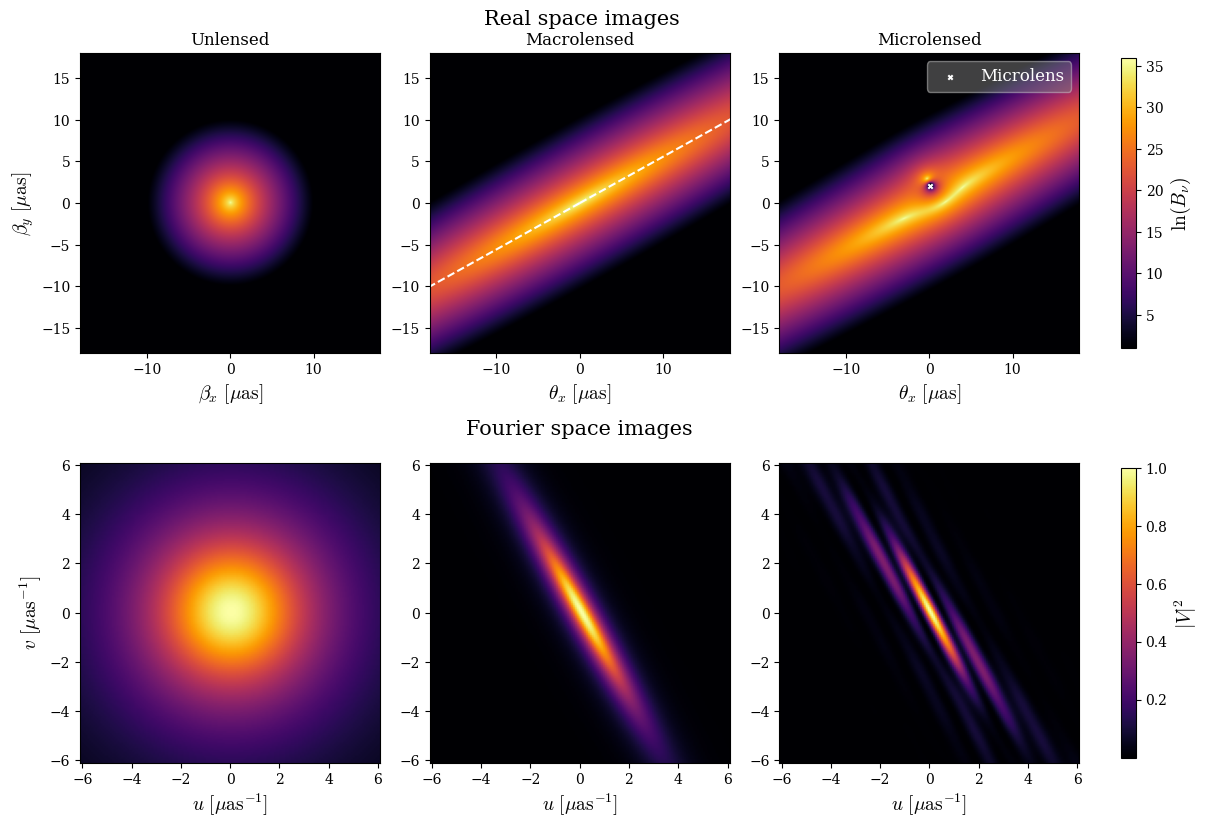

In [52]:
#Generate Figure 1

zoom = 50
ny, nx = corr_00_full.shape
cy, cx = ny//2, nx//2  # center
def zoom_in(arr, factor=zoom):
    half_y = ny // (2*factor)
    half_x = nx // (2*factor)
    return arr[cy-half_y:cy+half_y, cx-half_x:cx+half_x]

corr_00_z = zoom_in(corr_00_full)
corr_0_z  = zoom_in(corr_0_full)
corr_1_z  = zoom_in(corr_1_full)

# Make the figure
fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
fig.text(0.48, 1.019, r'Real space images', ha='center', va='top', fontsize=15, transform=fig.transFigure)
imlist = [im_00, im_0, im_1]
titles = [r"Unlensed", r"Macrolensed", r"Microlensed"]
vmin = 1 
vmax = np.max([im.max() for im in imlist])
for i, ax in enumerate(axes[0]):
    implot = ax.imshow(imlist[i], origin="lower", extent=[-theta_max*rad_to_arcsec, theta_max*rad_to_arcsec, -theta_max*rad_to_arcsec, theta_max*rad_to_arcsec], 
                       vmin=vmin, vmax=vmax, cmap="inferno")
    ax.set_xlabel(r"$\theta_x \ [\mu \text{as}]$", fontsize=14)
    if i == 0:
        ax.set_ylabel(r"$\theta_y \ [\mu \text{as}]$", fontsize=14)
    if i ==1:
        ax.plot((0, max_x[0][0]*rad_to_arcsec), (0,max_x[0][1]*rad_to_arcsec), color='white', linestyle='--')
        ax.plot((0, -max_x[0][0]*rad_to_arcsec), (0, -max_x[0][1]*rad_to_arcsec), color='white', linestyle='--')

    ax.set_title(titles[i])
    ax.set_xlim(-18, 18)
    ax.set_ylim(-18, 18)
cbar1 = fig.colorbar(implot, ax=axes[0, :], location="right", fraction=0.0145, pad=0.04)
cbar1.set_label(r"$\ln(B_\nu)$", fontsize=14)

imlist2 = [corr_00_z, corr_0_z, corr_1_z]
titles2 = [r"$|V_{00}|^2$", r"$|V_{0}|^2$", r"$|V_{1}|^2$"]
vmin2 = np.min([im.min() for im in imlist2])
vmax2 = np.max([im.max() for im in imlist2])
extent_z =np.array( [-umax/zoom, umax/zoom, -umax/zoom, umax/zoom])/rad_to_arcsec
#extent_z=[-umax/zoom*2, umax/zoom*2, -umax/zoom*2, umax/zoom*2]
for i, ax in enumerate(axes[1]):
    implot2 = ax.imshow(imlist2[i], origin="lower", extent=extent_z, vmin=vmin2, vmax=vmax2, cmap="inferno")
    ax.set_xlabel(r"$u \ [\mu \text{as}^{-1}]$", fontsize=14)
    if i == 0:
        ax.set_ylabel(r"$v \ [\mu \text{as}^{-1}]$", fontsize=14)
        
    #ax.set_title(titles2[i])
cbar2 = fig.colorbar(implot2, ax=axes[1, :], location="right", fraction=0.0145, pad=0.04)
cbar2.set_label(r"$|V|^2$", fontsize=14)
axes[1, 1].set_title("Fourier space images", fontsize=15, pad=20)

axes[0, 0].set_xlabel(r"$\beta_x \ [\mu \text{as}]$", fontsize=14)
axes[0, 0].set_ylabel(r"$\beta_y \ [\mu \text{as}]$", fontsize=14)
axes[0,2].scatter((arr_rands[0][0]-2e-10)*rad_to_arcsec, (arr_rands[0][1]-2e-10)*rad_to_arcsec, color='white', marker='x', s=10, label='Microlens')
axes[0,2].legend(fontsize=12, facecolor='gray', framealpha=.5,  labelcolor='white')
#plt.show()

plt.savefig('../Figures/basic_lensing.pdf', bbox_inches='tight')
FileLink('../Figures/basic_lensing.pdf')



In [53]:
## generate a second microlensed image at a more distant point for illustrative purposes in the appendix
m_stars = jnp.asarray([0.4])
arr_rands_far=(jnp.array([[4020], [4400]])*theta_step).reshape(1,2)
#arr_rands = jnp.array([[(positions[i][0])*theta_step, (positions[i][1])*theta_step]])
star_params_far = (m_stars, D_s, D_l, D_ls, theta_max, arr_rands_far)
_, beta_far = beta(g_params, star_params_far, arr_theta)
image_far, _, _=sparse_quasar_image(beta_far, theta_500, theta_max, beta_min, quasar_int_sparse)
_,_, corr_far_full=calcC_sparse(image_far, theta_step, ellipse=False)

corr_far=corr_far_full[vpts_8k, upts_8k] #this is the observations we'd actually see, not really necessary here
image_far = np.log(image_far.todense()+1e-40)

## lensed image - similar to above but iwht a more massive lens
m_stars = jnp.asarray([1.])
arr_rands=(jnp.array([[4010], [4200]])*theta_step).reshape(1,2)
star_params_mass = (m_stars, D_s, D_l, D_ls, theta_max, arr_rands)
_, beta_mass = beta(g_params, star_params_mass, arr_theta)
image_mass, _, _=sparse_quasar_image(beta_mass, theta_500, theta_max, beta_min, quasar_int_sparse)
_,_, corr_mass_full=calcC_sparse(image_mass, theta_step, ellipse=False)


corr_mass=corr_mass_full[vpts_8k, upts_8k] #these are the points we'd actually see, not really necessary here
image_mass = np.log(image_mass.todense()+1e-40) # add floor for plotting purposes

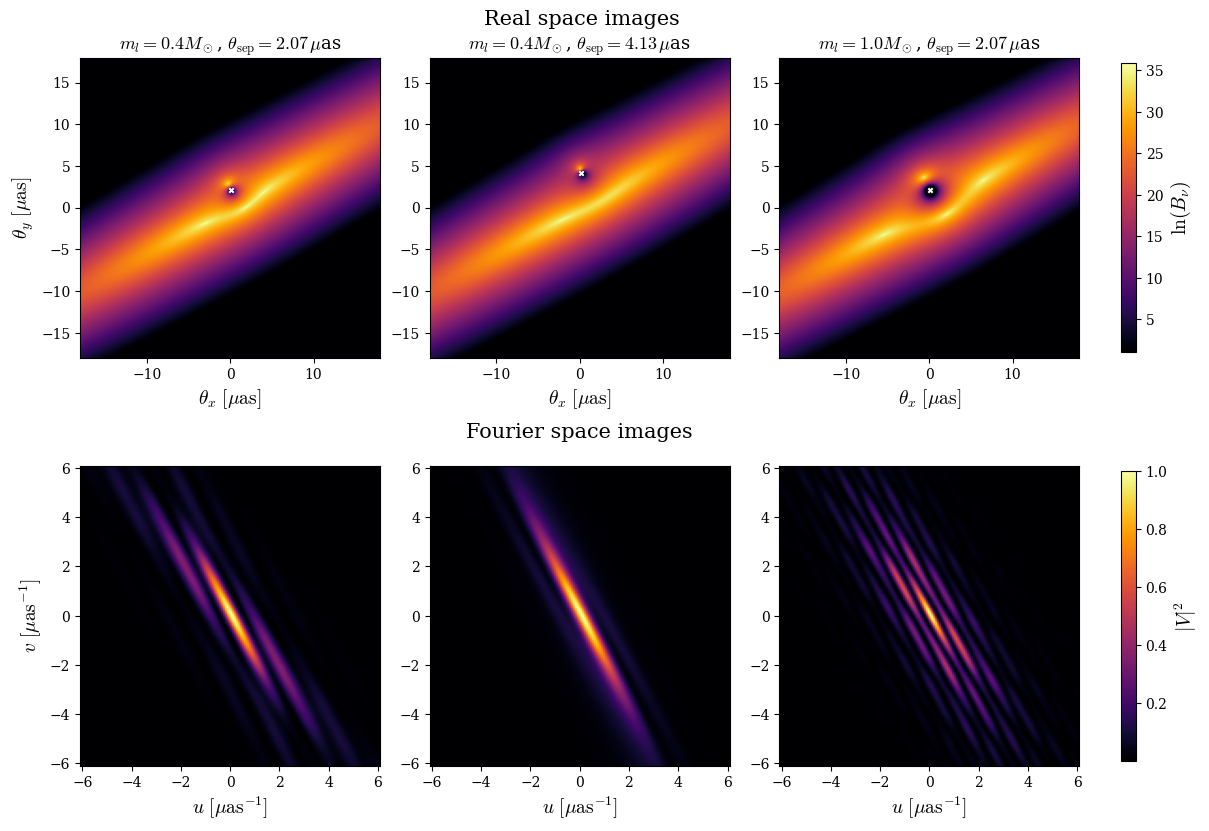

In [56]:
zoom = 50
ny, nx = corr_1_full.shape
cy, cx = ny//2, nx//2  # center
def zoom_in(arr, factor=zoom):
    half_y = ny // (2*factor)
    half_x = nx // (2*factor)
    return arr[cy-half_y:cy+half_y, cx-half_x:cx+half_x]

corr_far_z = zoom_in(corr_far_full)
corr_mass_z  = zoom_in(corr_mass_full)
corr_1_z  = zoom_in(corr_1_full)

# Make the figure
fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
fig.text(0.48, 1.022, r'Real space images', ha='center', va='top', fontsize=15, transform=fig.transFigure)
imlist = [im_1, image_far, image_mass]
theta_close=(np.linalg.norm(arr_rands-2e-10))*rad_to_arcsec
theta_far= (np.linalg.norm(arr_rands_far-2e-10))*rad_to_arcsec
titles = [f'$m_l=0.4M_\\odot$, $\\theta_{{\\rm sep}}={theta_close:.2f} \, \\mu $as',
          f'$m_l=0.4M_\\odot$, $\\theta_{{\\rm sep}}={theta_far:.2f} \, \\mu $as', 
          f'$m_l=1.0M_\\odot$, $\\theta_{{\\rm sep}}={theta_close:.2f} \, \\mu $as']

vmin = 1#min(im.min() for im in imlist)
vmax = np.max([im.max() for im in imlist])
for i, ax in enumerate(axes[0]):
    implot = ax.imshow(imlist[i], origin="lower", extent=[-theta_max*rad_to_arcsec, theta_max*rad_to_arcsec, -theta_max*rad_to_arcsec, theta_max*rad_to_arcsec], 
                       vmin=vmin, vmax=vmax, cmap="inferno")
    ax.set_xlabel(r"$\theta_x \ [\mu \text{as}]$", fontsize=14)
    if i == 0:
        ax.set_ylabel(r"$\theta_y \ [\mu \text{as}]$", fontsize=14)
    
    ax.set_title(titles[i], fontsize=13)
    ax.set_xlim(-18, 18)
    ax.set_ylim(-18, 18)
cbar1 = fig.colorbar(implot, ax=axes[0, :], location="right", fraction=0.0145, pad=0.04)
cbar1.set_label(r"$\ln(B_\nu)$", fontsize=14)
#axes[0, 1].set_title("Real space images", fontsize=14, pad=20)

imlist2 = [corr_1_z, corr_far_z, corr_mass_z]
titles2 = [r"$|V_{00}|^2$", r"$|V_{0}|^2$", r"$|V_{1}|^2$"]
vmin2 = np.min([im.min() for im in imlist2])
vmax2 = np.max([im.max() for im in imlist2])
extent_z =np.array( [-umax/zoom, umax/zoom, -umax/zoom, umax/zoom])/rad_to_arcsec
for i, ax in enumerate(axes[1]):
    implot2 = ax.imshow(imlist2[i], origin="lower", extent=extent_z, vmin=vmin2, vmax=vmax2, cmap="inferno")
    ax.set_xlabel(r"$u \ [\mu \text{as}^{-1}]$", fontsize=14)
    if i == 0:
        ax.set_ylabel(r"$v \ [\mu \text{as}^{-1}]$", fontsize=14)
        
    #ax.set_title(titles2[i])
cbar2 = fig.colorbar(implot2, ax=axes[1, :], location="right", fraction=0.0145, pad=0.04)
cbar2.set_label(r"$|V|^2$", fontsize=14)
axes[1, 1].set_title("Fourier space images", fontsize=15, pad=20)

axes[0,0].scatter((arr_rands[0][0]-2e-10)*rad_to_arcsec, (arr_rands[0][1]-2e-10)*rad_to_arcsec, color='white', marker='x', s=10)
axes[0,1].scatter((arr_rands_far[0][0]-2e-10)*rad_to_arcsec, (arr_rands_far[0][1]-2e-10)*rad_to_arcsec, color='white', marker='x', s=10)
axes[0,2].scatter((arr_rands[0][0]-2e-10)*rad_to_arcsec, (arr_rands[0][1]-2e-10)*rad_to_arcsec, color='white', marker='x', s=10)

#axes[0,2].legend(fontsize=12)
#plt.show()

plt.savefig('../Figures/lensing_comparison.pdf', bbox_inches='tight')
#FileLink('Figures/lensing_comparison.pdf')



In [65]:
# generate sampling points for illustrative purposes, far fewer points than we really use
u_vals = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(image_size, d=theta_step))/rad_to_arcsec
umax=np.max(u_vals)
a, b, phi, corr_pts=get_uv_elipse(corr_0_full, u_vals, u_vals, numpts=400)

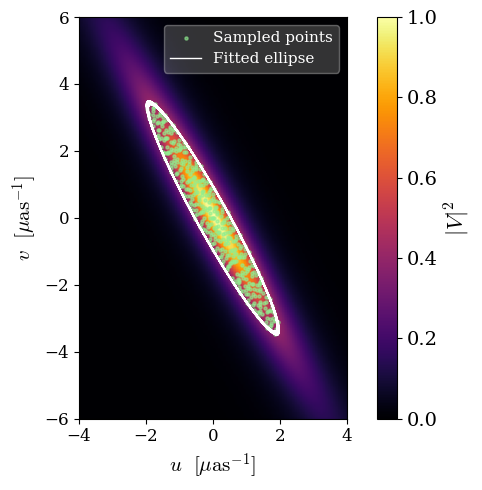

In [67]:
# plot the poitns over the quasar image in Fourier space 
fig, ax = plt.subplots(figsize=(7, 5))
    
# Show correlation function

extent =np.array( [-umax, umax, -umax, umax])
im=ax.imshow(corr_0_full, origin="lower", extent=extent, vmin=0, vmax=1, cmap="inferno")
cbar = plt.colorbar(im, ax=ax, fraction=.046)
cbar.set_label(r"$|V|^2$", fontsize=16)
cbar.ax.tick_params(labelsize=14)
ax.scatter(corr_pts[:, 1].T, corr_pts[:, 0].T, color='lightgreen', s=5, alpha=0.6, label='Sampled points')

# Plot ellipse boundary
t = np.linspace(0, 2*np.pi, 300)*rad_to_arcsec
ellipse_u = a * np.cos(t)
ellipse_v = b * np.sin(t)

rot = np.array([[np.cos(phi), -np.sin(phi)],
                [np.sin(phi),  np.cos(phi)]])
ellipse = rot @ np.vstack([ellipse_u, ellipse_v])
ax.plot(ellipse[1, :], ellipse[0, :], color='white', linewidth=1, label='Fitted ellipse')

ax.plot((0, 1*max_x[0][0]), (0, 1*max_x[0][1]), color='white', linestyle='--') #keep same angle just scale it up like crazy 
ax.plot((0, -1*max_x[0][0]), (0, -1*max_x[0][1]), color='white', linestyle='--') 

ax.set_xlabel(r"$u\ \ [\mu \text{as}^{-1}]$", fontsize=15)
ax.set_ylabel(r"$v\ \ [\mu \text{as}^{-1}]$", fontsize=15)

ax.tick_params(axis='both', which='major', labelsize=12)
ax.tick_params(axis='both', which='minor', labelsize=10)

ax.set_ylim(-6, 6)
ax.set_xlim(-4, 4)
ax.set_aspect('equal')
ax.legend(fontsize=11, labelcolor='white', facecolor='gray', framealpha=0.4)
plt.tight_layout()
#plt.show()
plt.savefig('../Figures/sampling.pdf', bbox_inches='tight')
#FileLink('Figures/sampling.pdf')


#### Check $\chi^2$ behaves as we would expect

In [179]:
def chi2(data, unlensed, error):
    return jnp.sum((data-unlensed)**2/error**2)

Chi^2 as a function of lens distance to see where we can ID microlensing with a single observation. This is just a check that this is behaving as we would expect, and is an intermediate result

In [19]:
# 0.4 solar masses
m_stars = jnp.asarray([0.4])
m_stars_1 = jnp.asarray([1.0])

fracs=[0, .1, .2, .4, .6, .7, .8,.9, 1,1.1, 1.2, 1.3, 1.4, 1.45, 1.5,1.55, 1.6,1.65, 1.7, 1.75, 1.8,1.9, 2, 2.1]
chi2s_04=[]
chi2s_10=[]
for frac in fracs:
    positions = place_star_radial(m_stars, frac, image_size=image_size)# (positions_plot / (theta_step * image_size)) + 0.5
    positions_1 = place_star_radial(m_stars_1, frac, image_size=image_size)
    arr_rands = jnp.array([[(positions[0][0])*theta_step, (positions[0][1])*theta_step]])
    arr_rands_1 = jnp.array([[(positions_1[0][0])*theta_step, (positions_1[0][1])*theta_step]])

    star_params_4 = (m_stars, D_s, D_l, D_ls, theta_max, arr_rands)
    star_params_1 = (m_stars_1, D_s, D_l, D_ls, theta_max, arr_rands_1)

    _, beta_1 = beta(g_params, star_params_1, arr_theta)
    image_1, _, _=sparse_quasar_image(beta_1, theta_500, theta_max, beta_min, quasar_int_sparse)
    _,_, corr_here1_full=calcC_sparse(image_1, theta_step, ellipse=False)
    corr_here1=corr_here1_full[vpts_8k, upts_8k]
    chi2s_10.append(chi2(corr_here1, corr_0, (sigma_C/np.sqrt(10))))

    _, beta_4 = beta(g_params, star_params_4, arr_theta)
    image_4, _, _=sparse_quasar_image(beta_4, theta_500, theta_max, beta_min, quasar_int_sparse)
    _,_, corr_here_full=calcC_sparse(image_4, theta_step, ellipse=False)
    corr_here=corr_here_full[vpts_8k, upts_8k]
    chi2s_04.append(chi2(corr_here, corr_0, (sigma_C/np.sqrt(10))))

# Timescales

In [8]:
def get_average_timescale(velocity, B_matrix, zl, dl, N, max_dist, r_det, n_its=100000):
    """
    Average detectable time for lenses uniformly distributed in impact parameter.

    Parameters
    ----------
    velocity : float
        Transverse velocity [km/s].
    B_matrix : array
        Lens mapping matrix.
    zl : float
        Lens redshift.
    dl : float
        Lens angular diameter distance [cm].
    N : float
        Expected number of detectable stars.
    r_det : float
        Detection radius [radians].
    max_dist: fload
        area we care about in the detection region. <=r_det
    n_its : int
        Number of Monte Carlo samples.

    Returns
    -------
    T_cross : array
        Detectable durations [yr].
    T_wait : array
        Waiting times [yr].
    """

    rng = np.random.default_rng()

    # impact parameter distribution for random trajectories
    fid_rad = rng.uniform(0, max_dist, size=n_its)

    # random velocity direction
    vel_angle = rng.uniform(0, 2*np.pi, size=n_its)

    v_x = velocity * np.cos(vel_angle)
    v_y = velocity * np.sin(vel_angle)

    v_rest = np.stack([v_x, v_y], axis=-1) * km_to_cm

    # angular velocity [rad/s]
    mu_lensed = get_velocities(v_rest, B_matrix, zl, dl)
    mu_lensed = np.linalg.norm(mu_lensed, axis=1)

    # angular crossing length [rad]
    theta_cross = 2 * np.sqrt(r_det**2 - fid_rad**2)

    # crossing time
    T_cross = np.mean(theta_cross / mu_lensed / (365.25 * 24 * 3600))

    N_real=N*(max_dist/r_det)**2
    T_wait = T_cross / N_real

    return T_cross, T_wait

def get_velocities(v_rest, B_matrix, redshift, lens_dist):
    """
    Apparent angular proper motion of a lens star in the image-fixed frame.

    CONVENTION (paper Sec. 3.2): the full relative source--lens motion is attributed
    to the lens population, and we work in the frame where the quasar macroimage is
    stationary by construction.  Relative motion displaces the macroimage, amplified
    in the image plane by B = A^{-1}; boosting to the image-fixed frame transfers
    that amplification to the apparent lens motion:
        nu_tilde = B_matrix @ [ v_perp / ((1+z_l) D_l) ].
    Returns the apparent proper motion in rad per unit time (units of
    lens_dist / velocity).  Pass B_matrix = identity to obtain the unlensed rate.
    """
    mu_rest = v_rest / (1 + redshift) / lens_dist

    return mu_rest @ B_matrix.T
seconds_year=31536000
km_to_cm = 1e5
theta_E_1 = np.array([np.sqrt(4 * G * (2e33) / c**2 * D_ls / (D_s * D_l))]) 
theta_E_4 = np.array([np.sqrt(4 * G * (0.4*2e33) / c**2 * D_ls / (D_s * D_l))]) 


In [9]:
# kappa values are here: https://arxiv.org/pdf/2303.11987
kappa_star= 0.04 #1.09 #dimensionless, we want this over kappa_crit
kappa_crit=(c**2/(4*np.pi*G))*(D_s/(D_l*D_ls)) # g/cm^2
Sigma_star=kappa_star*kappa_crit
avg_star_mass=.4*u.solMass.to(u.g)
n=(Sigma_star/avg_star_mass) #stars/cm^2
bulk_vel=400
bulk_vel_err=100
vel_disp=178
vel_disp_err=35

In [10]:
r_det=4.5*theta_E_4
N=n*np.pi*(D_l*r_det)**2
vel=np.sqrt(bulk_vel**2+vel_disp**2)
print('N=', N)
get_average_timescale(vel, B_matrix, z_l, D_l, N, r_det, r_det)

N= [0.81472136]


(np.float64(49.4389451017503), array([60.68202866]))

In [11]:
get_average_timescale(vel, B_matrix, z_l, D_l, N, 2.5*theta_E_4, r_det, )

(np.float64(59.36896998027198), array([236.09969184]))